# 03 — Transportation noise exposure (Ohio counties)

**Question:** What share of each Ohio county's residents live in areas with high transportation noise?

**Data:**
- **Noise:** BTS National Transportation Noise Map, 2022/2023, Continental U.S. road, rail, and aviation combined (aviation and rail 2022, road 2023). 24-hour equivalent A-weighted sound level (LAeq, dBA) on a 30 m grid. Levels below 45 dBA are not mapped.
- **Population:** 2020 Census blocks for Ohio (TIGER/Line 2022 release, `tl_2022_39_tabblock20`). Block population (`POP20`) and internal points (`INTPTLAT20`, `INTPTLON20`).

**Method:**
1. Look up the noise level at each block's internal point.
2. For each county, compute the share of residents living in blocks at or above 45, 55, and 65 dBA.

**Output:** one row per county with the percent of residents exposed at each threshold, saved to `data/processed/`.

**Note:** Unmapped areas (<45 dBA) count as below every threshold. This avoids assigning an arbitrary noise level to quiet areas.

In [1]:
from pathlib import Path

NOISE_DIR  = Path("../data/large/bts_2022_combined")
root       = NOISE_DIR / "CONUS_rail_road_and_aviation_noise_2022"
GDB        = root / "CONUS_rail_road_aviation_noise.Overviews" / "CONUS_rail_road_aviation_noise.gdb"
BLOCKS_PATH = Path("../data/large/census_blocks/tl_2022_39_tabblock20")
PROCESSED  = Path("../data/processed")

In [2]:
import rasterio

GDB = root / "CONUS_rail_road_aviation_noise.Overviews" / "CONUS_rail_road_aviation_noise.gdb"

with rasterio.open(GDB) as gdb_src:
    OH_PATH = next(sd for sd in gdb_src.subdatasets if sd.endswith(":OH_rail_road_aviation_noise"))

with rasterio.open(OH_PATH) as src:
    print("CRS:", src.crs)
    print("Cell size:", src.res)
    print("Width x height:", src.width, "x", src.height)
    print("Data type:", src.dtypes, "| NoData value:", src.nodata)
    print("Bounds:", src.bounds)
    print("Overview levels:", src.overviews(1))

CRS: ESRI:102039
Cell size: (29.99999999999999, 29.999999999999982)
Width x height: 12330 x 14059
Data type: ('float32',) | NoData value: 3.3999999521443642e+38
Bounds: BoundingBox(left=922758.1280730321, bottom=1790159.5734320304, right=1292658.128073032, top=2211929.57343203)
Overview levels: [2, 4, 8, 16, 32, 64]


c:\Users\888am\projects\noise-cvd\.venv\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Min / max dBA: 45.000023 107.33821
Share of cells with data: 0.189


c:\Users\888am\projects\noise-cvd\.venv\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


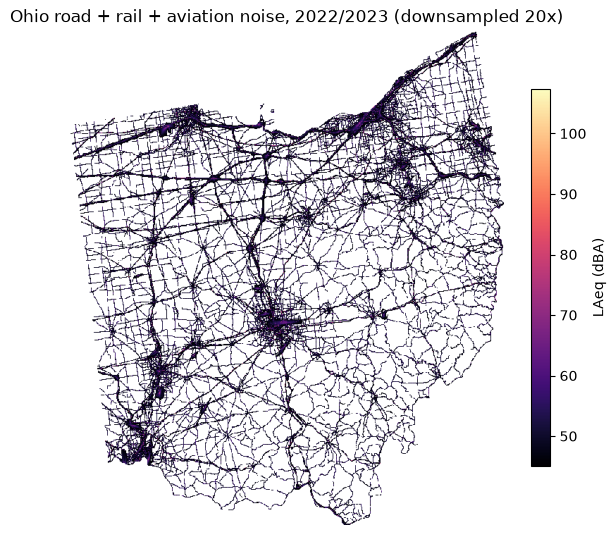

In [3]:
import matplotlib.pyplot as plt

factor = 20
with rasterio.open(OH_PATH) as src:
    small = src.read(1, out_shape=(src.height // factor, src.width // factor), masked=True)

print("Min / max dBA:", small.min(), small.max())
print("Share of cells with data:", round(1 - small.mask.mean(), 3))

plt.figure(figsize=(7, 7))
plt.imshow(small, cmap="magma")
plt.colorbar(label="LAeq (dBA)", shrink=0.7)
plt.title("Ohio road + rail + aviation noise, 2022/2023 (downsampled 20x)")
plt.axis("off")
plt.show()

In [4]:
import geopandas as gpd
import numpy as np

blocks = gpd.read_file(
    BLOCKS_PATH,
    columns=["GEOID20", "POP20", "INTPTLAT20", "INTPTLON20"],
    ignore_geometry=True,   # skip the block outlines; we only need the internal points
)

print(f"{len(blocks):,} blocks")
print(f"Total population: {blocks['POP20'].sum():,}")        # Ohio's 2020 count: 11,799,448
print(f"Share of blocks with zero population: {(blocks['POP20'] == 0).mean():.3f}")

assert blocks["POP20"].sum() == 11_799_448, blocks["POP20"].sum()

276,428 blocks
Total population: 11,799,448
Share of blocks with zero population: 0.205


In [5]:
#Keep populated blocks, add county FIPS, and convert coordinates.

blocks = blocks[blocks["POP20"] > 0].copy()
blocks["county_fips"] = blocks["GEOID20"].str[:5]   # first 5 digits = state (39) + county

pts = gpd.GeoDataFrame(
    blocks,
    geometry=gpd.points_from_xy(blocks["INTPTLON20"].astype(float), blocks["INTPTLAT20"].astype(float)),
    crs="EPSG:4269",   # NAD83 latitude/longitude, the system TIGER/Line uses
)

with rasterio.open(OH_PATH) as src:
    pts = pts.to_crs(src.crs.to_wkt())   # convert to the raster's Albers meters
    b = src.bounds

inside = pts.geometry.x.between(b.left, b.right) & pts.geometry.y.between(b.bottom, b.top)
assert inside.all(), f"{(~inside).sum()} points fall outside the raster"

In [6]:
import time

coords = list(zip(pts.geometry.x, pts.geometry.y))
t0 = time.time()
with rasterio.open(OH_PATH) as src:
    vals = np.array([v[0] for v in src.sample(coords)], dtype="float64")
print(f"Sampled {len(vals):,} points in {time.time() - t0:.0f} s")

vals[vals > 1e30] = np.nan            # NoData (3.4e38) -> missing, meaning below 45 dBA
assert np.nanmax(vals) < 120, np.nanmax(vals)
pts["laeq"] = vals

print(f"Share of populated blocks with mapped noise (>=45 dBA): {np.isfinite(vals).mean():.3f}")
pts["laeq"].describe()

Sampled 219,669 points in 6 s
Share of populated blocks with mapped noise (>=45 dBA): 0.208


count    45587.000000
mean        49.883288
std          4.511018
min         45.000061
25%         46.657406
50%         48.735458
75%         51.818447
max        107.146370
Name: laeq, dtype: float64

In [7]:
THRESHOLDS = [45, 50, 55, 65]

for t in THRESHOLDS:
    pts[f"pop_ge{t}"] = pts["POP20"] * (pts["laeq"] >= t)

pts[["county_fips", "POP20", "laeq", "pop_ge45", "pop_ge55", "pop_ge65"]].head(10)

,county_fips,POP20,laeq,pop_ge45,pop_ge55,pop_ge65
1,39013,19,NaN,0,0,0
2,39013,3,NaN,0,0,0
3,39013,7,NaN,0,0,0
5,39013,41,NaN,0,0,0
6,39013,21,NaN,0,0,0
7,39013,49,NaN,0,0,0
9,39013,31,NaN,0,0,0
10,39013,7,NaN,0,0,0
12,39013,12,NaN,0,0,0
15,39013,37,NaN,0,0,0


In [8]:
cols = ["POP20"] + [f"pop_ge{t}" for t in THRESHOLDS]
county = pts.groupby("county_fips")[cols].sum()

for t in THRESHOLDS:
    county[f"pct_ge{t}"] = county[f"pop_ge{t}"] / county["POP20"]

county.head()

,POP20,pop_ge45,pop_ge50,pop_ge55,pop_ge65,pct_ge45,pct_ge50,pct_ge55,pct_ge65
county_fips,,,,,,,,,
39001,27477,453,195,77,0,0.016487,0.007097,0.002802,0.000000
39003,102206,22240,4206,1149,423,0.217600,0.041152,0.011242,0.004139
39005,52447,2795,1161,379,58,0.053292,0.022137,0.007226,0.001106
39007,97574,31763,9590,1318,131,0.325527,0.098284,0.013508,0.001343
39009,62431,1810,955,526,292,0.028992,0.015297,0.008425,0.004677


In [9]:
# One row per Ohio county
assert len(county) == 88, len(county)

# Every person counted exactly once: county totals add back to the state total
assert county["POP20"].sum() == 11_799_448, county["POP20"].sum()

# Shares must be between 0 and 1
pct_cols = [f"pct_ge{t}" for t in THRESHOLDS]
assert county[pct_cols].ge(0).all().all() and county[pct_cols].le(1).all().all()

# Logical ordering: anyone at >=65 dBA is also at >=55 and >=45
assert (county["pct_ge45"] >= county["pct_ge55"]).all()
assert (county["pct_ge55"] >= county["pct_ge65"]).all()

county[pct_cols].describe().round(3)

,pct_ge45,pct_ge50,pct_ge55,pct_ge65
count,88.000,88.000,88.000,88.000
mean,0.142,0.049,0.013,0.001
std,0.128,0.051,0.012,0.002
min,0.001,0.000,0.000,0.000
25%,0.036,0.013,0.004,0.000
50%,0.100,0.027,0.009,0.001
75%,0.219,0.075,0.017,0.002
max,0.520,0.206,0.059,0.009


In [10]:
import pandas as pd

RAW = Path("../data/raw")
names = (pd.read_csv(RAW / "places_2025_county_OH.csv", dtype={"locationid": str})
           [["locationid", "locationname"]].drop_duplicates()
           .rename(columns={"locationid": "county_fips", "locationname": "county"}))

county = county.reset_index().merge(names, on="county_fips", how="left")
assert county["county"].notna().all()

ranked = county.sort_values("pct_ge55", ascending=False)[["county", "POP20"] + pct_cols]
display(ranked.head(5).round(3))
display(ranked.tail(5).round(3))

,county,POP20,pct_ge45,pct_ge50,pct_ge55,pct_ge65
73,Seneca,55069,0.411,0.189,0.059,0.005
16,Crawford,42025,0.447,0.206,0.050,0.004
61,Ottawa,40364,0.388,0.173,0.046,0.005
38,Huron,58565,0.315,0.153,0.044,0.002
67,Preble,40999,0.259,0.134,0.040,0.003


,county,POP20,pct_ge45,pct_ge50,pct_ge55,pct_ge65
79,Union,62784,0.016,0.006,0.001,0.000
51,Medina,182470,0.019,0.005,0.001,0.000
60,Noble,14115,0.016,0.006,0.001,0.001
52,Meigs,22210,0.013,0.007,0.000,0.000
27,Geauga,95397,0.001,0.000,0.000,0.000


In [11]:
#Diagnostic: check a few counties of interest, including the top and bottom ranks for >=45 dBA

from rasterio.windows import from_bounds

check_names = ["Cuyahoga", "Franklin", "Hamilton", "Geauga", "Medina", "Seneca", "Crawford"]
ranks = county["pct_ge45"].rank(ascending=False)
rows = []

with rasterio.open(OH_PATH) as src:
    for name in check_names:
        is_c = county["county"] == name
        fips = county.loc[is_c, "county_fips"].iloc[0]
        sub = pts[pts["county_fips"] == fips]
        # Read only the raster window covering this county's block points
        win = from_bounds(*sub.total_bounds, transform=src.transform)
        arr = src.read(1, window=win, masked=True)
        rows.append({
            "county": name,
            "rank_ge45 (of 88)": int(ranks[is_c].iloc[0]),
            "pop_share_ge45": county.loc[is_c, "pct_ge45"].iloc[0],
            "area_share_ge45": 1 - arr.mask.mean(),
        })

pd.DataFrame(rows).round(3)

,county,rank_ge45 (of 88),pop_share_ge45,area_share_ge45
0,Cuyahoga,8,0.352,0.243
1,Franklin,15,0.288,0.270
2,Hamilton,24,0.211,0.220
3,Geauga,88,0.001,0.063
4,Medina,77,0.019,0.095
5,Seneca,5,0.411,0.135
6,Crawford,3,0.447,0.106


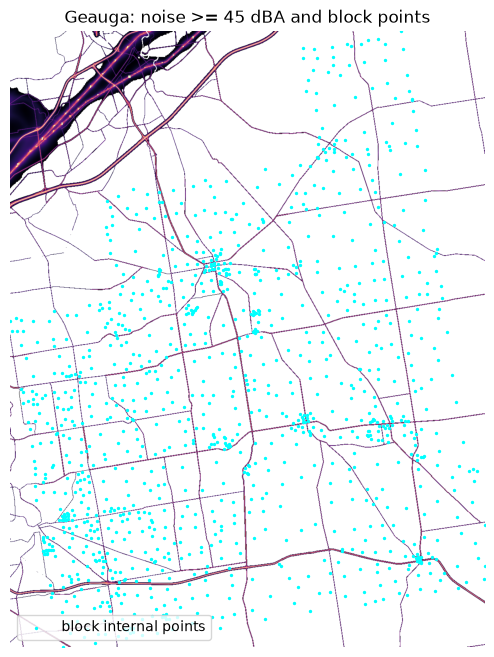

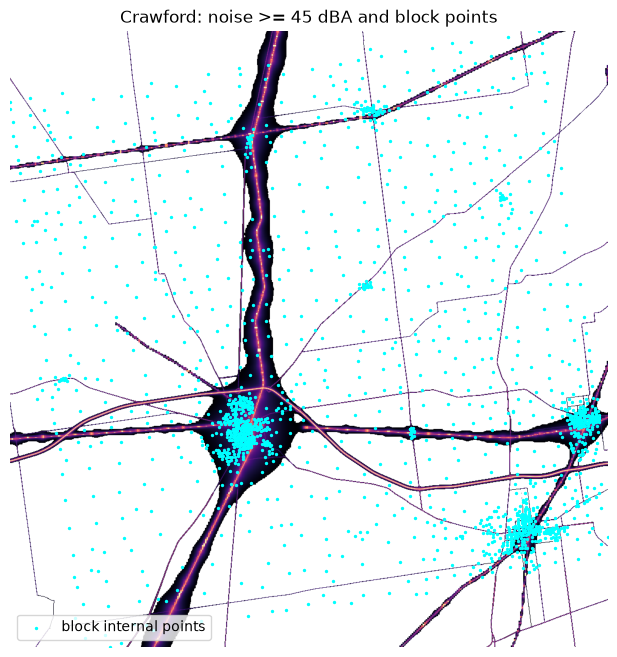

In [12]:
from rasterio.windows import bounds as win_bounds

def show_county(name):
    fips = county.loc[county["county"] == name, "county_fips"].iloc[0]
    sub = pts[pts["county_fips"] == fips]
    with rasterio.open(OH_PATH) as src:
        win = from_bounds(*sub.total_bounds, transform=src.transform)
        arr = src.read(1, window=win, masked=True)
        left, bottom, right, top = win_bounds(win, src.transform)
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(arr.filled(np.nan), extent=(left, right, bottom, top), cmap="magma", vmin=45, vmax=75)
    ax.scatter(sub.geometry.x, sub.geometry.y, s=2, c="cyan", label="block internal points")
    ax.set_title(f"{name}: noise >= 45 dBA and block points")
    ax.legend(loc="lower left")
    ax.axis("off")
    fig.savefig(f"../outputs/blockpoints_{name.lower()}.png", dpi=200, bbox_inches="tight")
    plt.show()

show_county("Geauga")
show_county("Crawford")

In [13]:
county.to_csv(PROCESSED / "noise_oh_county_2022.csv", index=False)

## Interpretation

### Findings
- Noise was looked up at the internal points of **219,669 populated census blocks** (all of Ohio's 11,799,448 residents). Only **20.8%** of these blocks fall in mapped noise (≥45 dBA); among those, the median level is 48.7 dBA.
- Share of county residents exposed, across Ohio's 88 counties:

| Threshold | Median county | Middle 50% of counties | Max |
|---|---|---|---|
| ≥45 dBA | 10.0% | 3.6% – 21.9% | 52.0% |
| ≥50 dBA | 2.7% | 1.3% – 7.5% | 20.6% |
| ≥55 dBA | 0.9% | 0.4% – 1.7% | 5.9% |
| ≥65 dBA | 0.1% | 0.0% – 0.2% | 0.9% |

- The most exposed counties at ≥45 dBA are small rural counties in north-central Ohio (Crawford 44.7%, Seneca 41.1%), ahead of the large urban counties (Cuyahoga 35.2%, rank 8; Franklin 28.8%, rank 15; Hamilton 21.1%, rank 24). The least exposed is Geauga (0.1%).

### What the diagnostic revealed
Comparing the share of *residents* exposed with the share of *land* exposed (≥45 dBA) showed two different patterns:

| County | Residents exposed | Land exposed |
|---|---|---|
| Geauga | 0.1% | 6.3% |
| Medina | 1.9% | 9.5% |
| Crawford | 44.7% | 10.6% |
| Seneca | 41.1% | 13.5% |
| Cuyahoga | 35.2% | 24.3% |

- **Exurban counties (Geauga, Medina):** noise exists, but block internal points fall mid-block, away from the roads where rural homes are actually located. Mapping the points confirmed this. The internal-point method therefore **underestimates exposure in counties with large rural blocks**.
- **Rail-junction counties (Crawford, Seneca):** residents are concentrated in towns (Bucyrus, Galion, Crestline; Tiffin, Fostoria) that sit inside wide noise bands. The bands' width suggests train-horn noise at grade crossings, to be confirmed with the rail-only layer.
- **Urban counties:** small blocks keep internal points close to streets, so residents exposed ≥ land exposed, as expected.
- This rules out a data gap in the BTS map (Geauga has mapped noise).

### Limitations
- **Population location:** a block's whole population is assigned to one internal point, which misrepresents where people live in large rural blocks.
- **BTS model coverage:** local residential streets are not modeled, and urban roads are assigned low speeds (e.g., 21 mph for urban principal arterials vs. 55 mph rural), likely understating urban road noise.
- **Rural–urban confounding:** exposure is partly driven by rurality, and rural Ohio counties tend to have higher CVD mortality, so the analysis must adjust for urbanicity.
- **Privacy-adjusted counts:** block populations include Census disclosure-avoidance noise; errors largely cancel at the county level.

### Decisions
- **Thresholds:** ≥45, ≥50, and ≥55 dBA for analysis. ≥65 dBA dropped because it barely varies across counties (median 0.1%). 50 dBA was added after seeing the distribution of block noise values. All threshold choices were made **before linking noise to any health outcome**.
- **Method:** this internal-point exposure is kept as a **sensitivity analysis**. The primary exposure will be **building-weighted** (notebook 04), which places population at building locations.

### Output
`data/processed/noise_oh_county_2022.csv`: one row per county with population and the share exposed at each threshold (internal-point method).